# 02 — Preprocessing & Training

Uses the clean splits from `01_eda` (`splits/*.csv`).
Preprocessing decisions come from the EDA conclusions table.

In [1]:
from pathlib import Path
import random
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

ROOT = Path("..")
SPLITS_DIR = ROOT / "splits"
IMG_SIZE = 224
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

import sys
sys.path.insert(0, str(ROOT.resolve()))

%load_ext autoreload
%autoreload 2

from src.data import CLASSES, crop_black_borders, get_transforms, BrainMRIDataset
from src.model import build_model, save_checkpoint, load_checkpoint, train_one_epoch, evaluate

cuda


In [2]:
splits = {name: pd.read_csv(SPLITS_DIR / f"{name}.csv") for name in ["train", "val", "test"]}

assert CLASSES == sorted(splits["train"]["label"].unique()), "CLASSES mismatch!"
class_to_idx = {c: i for i, c in enumerate(CLASSES)}

for name, df in splits.items():
    print(f"{name:>5}: {len(df)} images")
print(class_to_idx)

train: 4214 images
  val: 903 images
 test: 903 images
{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


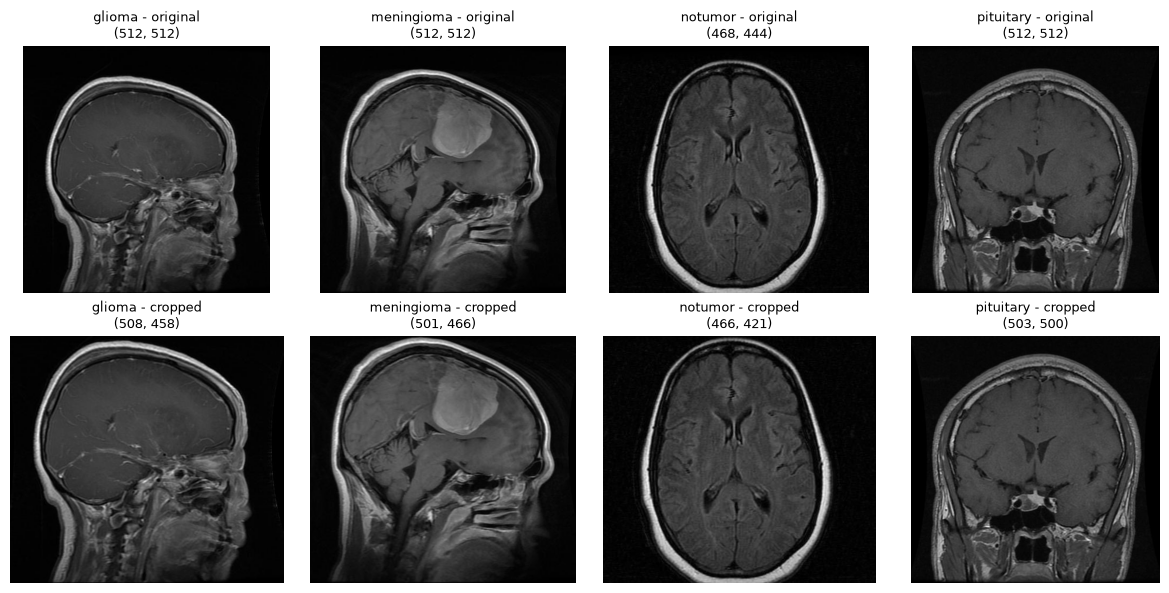

In [3]:
sample = splits["train"].groupby("label").sample(1, random_state=SEED)
fig, axes = plt.subplots(2, len(sample), figsize=(12, 6))

for j, (_, row) in enumerate(sample.iterrows()):
    img = Image.open(ROOT / row["path"]).convert("RGB")
    cropped = crop_black_borders(img)
    for i, (im, tag) in enumerate([(img, "original"), (cropped, "cropped")]):
        axes[i, j].imshow(im)
        axes[i, j].set_title(f'{row["label"]} - {tag}\n{im.size}', fontsize=9)
        axes[i, j].axis("off")
plt.tight_layout()
plt.show()

             count   mean    std    min    25%    50%    75%  max
label                                                            
glioma      1242.0  0.703  0.157  0.358  0.571  0.684  0.845  1.0
meningioma  1032.0  0.757  0.156  0.315  0.644  0.781  0.882  1.0
notumor      716.0  0.880  0.156  0.388  0.814  0.957  1.000  1.0
pituitary   1224.0  0.907  0.113  0.565  0.890  0.946  0.988  1.0


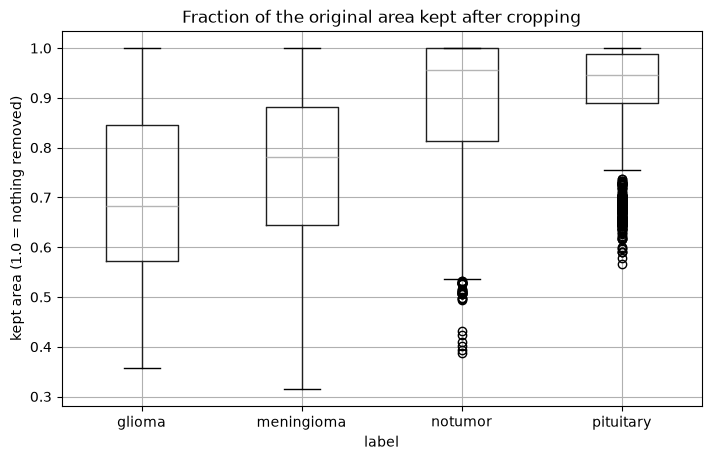

In [4]:
def crop_ratio(path):
    """Fraction of the original area kept after cropping"""
    with Image.open(ROOT / path) as img:
        cropped = crop_black_borders(img)
        return (cropped.width * cropped.height) / (img.width * img.height)

train_df = splits["train"].copy()
train_df["kept_area"] = [crop_ratio(p) for p in train_df["path"]]

print(train_df.groupby("label")["kept_area"].describe().round(3))

train_df.boxplot(column="kept_area", by="label", figsize=(8, 5))
plt.suptitle("")
plt.title("Fraction of the original area kept after cropping")
plt.ylabel("kept area (1.0 = nothing removed)")
plt.show()

### Observations: black-border cropping

- The crop removes much more black frame from **glioma** (median kept area ~0.68)
  and **meningioma** (~0.78) than from **notumor** and **pituitary** (~0.95).
- This matches the EDA brightness ranking (glioma darkest, notumor brightest):
  part of the class-dependent brightness was caused by **framing**, not anatomy.
- → Cropping removes a shortcut (amount of black border ≈ class).
- notumor has a very wide spread (0.4–1.0): consistent with multiple source datasets.
- Residual effect: after resizing, glioma/meningioma brains are zoomed in more → check with Grad-CAM.

           mean_before                                            mean_after  \
                 count  mean   std   min   25%   50%   75%    max      count   
label                                                                          
glioma          1242.0  34.6  11.3  15.3  26.8  33.0  39.7  122.3     1242.0   
meningioma      1032.0  43.2  13.6  18.6  35.1  40.8  46.4  120.2     1032.0   
notumor          716.0  62.7  22.1  18.3  47.3  58.3  76.2  126.7      716.0   
pituitary       1224.0  49.1   8.5  24.7  43.4  49.6  54.0  102.3     1224.0   

                                                       
            mean   std   min   25%   50%   75%    max  
label                                                  
glioma      48.7   9.3  25.7  43.1  47.6  52.8  122.3  
meningioma  56.7  11.7  30.7  50.0  54.3  60.2  120.2  
notumor     71.4  22.0  27.4  55.4  68.8  87.8  138.2  
pituitary   54.2   7.3  31.1  49.4  53.5  58.8  102.3  


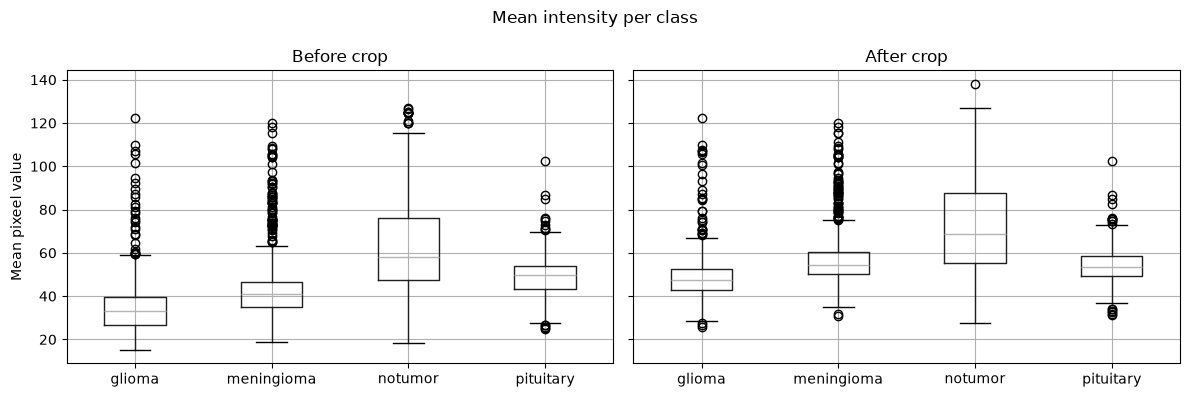

In [5]:
def mean_intensity(img):
    return np.asanyarray(img.convert("L"), dtype = np.float32).mean()

def brightness_before_after(path):
    with Image.open(ROOT / path) as img:
        return mean_intensity(img), mean_intensity(crop_black_borders(img))

train_df[["mean_before", "mean_after"]] = [brightness_before_after(p) for p in train_df["path"]]

print(train_df.groupby("label")[["mean_before", "mean_after"]].describe().round(1))

fig,axes = plt.subplots(1,2, figsize=(12,4), sharey = True)
for ax, col, title in zip(axes, ["mean_before", "mean_after"], ["Before crop", "After crop"]):
    train_df.boxplot(column=col, by="label", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")

axes[0].set_ylabel("Mean pixeel value")
plt.suptitle("Mean intensity per class")
plt.tight_layout()
plt.show()


### Observations: brightness after cropping

- After cropping, **glioma, meningioma and pituitary converge** (medians ~47–55, boxes overlap):
  their brightness gap was mostly caused by the black frame.
- **notumor stays clearly brighter** (median ~69): this is a **source/style bias**
  (higher contrast, T2 sequences), not framing → cropping cannot fix it.
- → Mitigation: per-image normalization + brightness/contrast augmentation (block 2).
- → notumor is the class where shortcut learning is most likely: priority target for Grad-CAM.

## Transforms & Dataset

Pipeline (from EDA decisions): RGB → crop black borders → resize 224×224 → augmentation (train only) → per-image normalization.

In [6]:
train_tfms = get_transforms(train=True)
eval_tfms = get_transforms(train=False)

In [7]:
train_ds = BrainMRIDataset(splits["train"], ROOT, train_tfms)
val_ds = BrainMRIDataset(splits["val"], ROOT, eval_tfms)
test_ds = BrainMRIDataset(splits["test"], ROOT, eval_tfms)

x, y = train_ds[0]
print(f"shape: {x.shape}, dtype: {x.dtype}, label: {y} ({CLASSES[y]})")
print(f"mean: {x.mean():.3f}, std: {x.std():.3f}")

shape: torch.Size([3, 224, 224]), dtype: torch.float32, label: 3 (pituitary)
mean: 0.000, std: 1.000


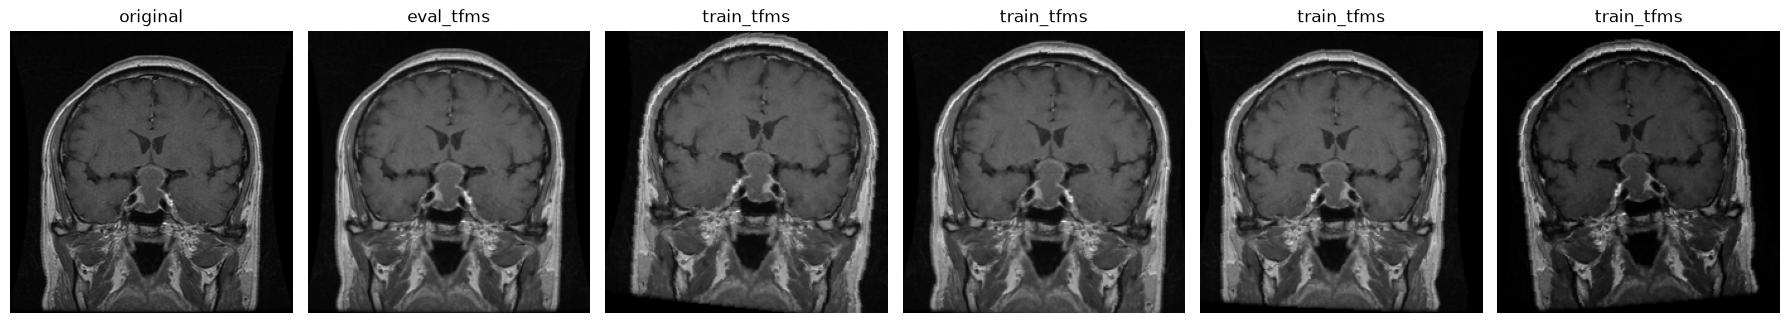

In [8]:
def to_display(x):
    """Tensor (C,H,W), normalized -> array (H,W,C) in [0,1] for imshow"""
    x = x.permute(1,2,0)
    return (x - x.min()) / (x.max() - x.min())

idx = 0
original = Image.open(ROOT / train_ds.paths[idx]).convert("RGB")

fig, axes = plt.subplots(1,6, figsize=(18, 3.5))
axes[0].imshow(original)
axes[0].set_title("original")
axes[1].imshow(to_display(eval_tfms(original)))
axes[1].set_title("eval_tfms")

for ax in axes[2:]:
    ax.imshow(to_display(train_ds[idx][0]))
    ax.set_title("train_tfms")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## DataLoaders

Batches of 32 images. Train is shuffled every epoch; val/test keep a fixed order.

In [9]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32
NUM_WORKERS = 4     # works because Dataset/transforms are imported from src/

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True,
    generator=torch.Generator().manual_seed(SEED),
)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)

print(f"batches per epoch -> train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}")

batches per epoch -> train: 132, val: 29, test: 29


images: torch.Size([32, 3, 224, 224]), torch.float32
labels: torch.Size([32]), torch.int64
per class in this batch: {'glioma': 12, 'meningioma': 8, 'notumor': 3, 'pituitary': 9}


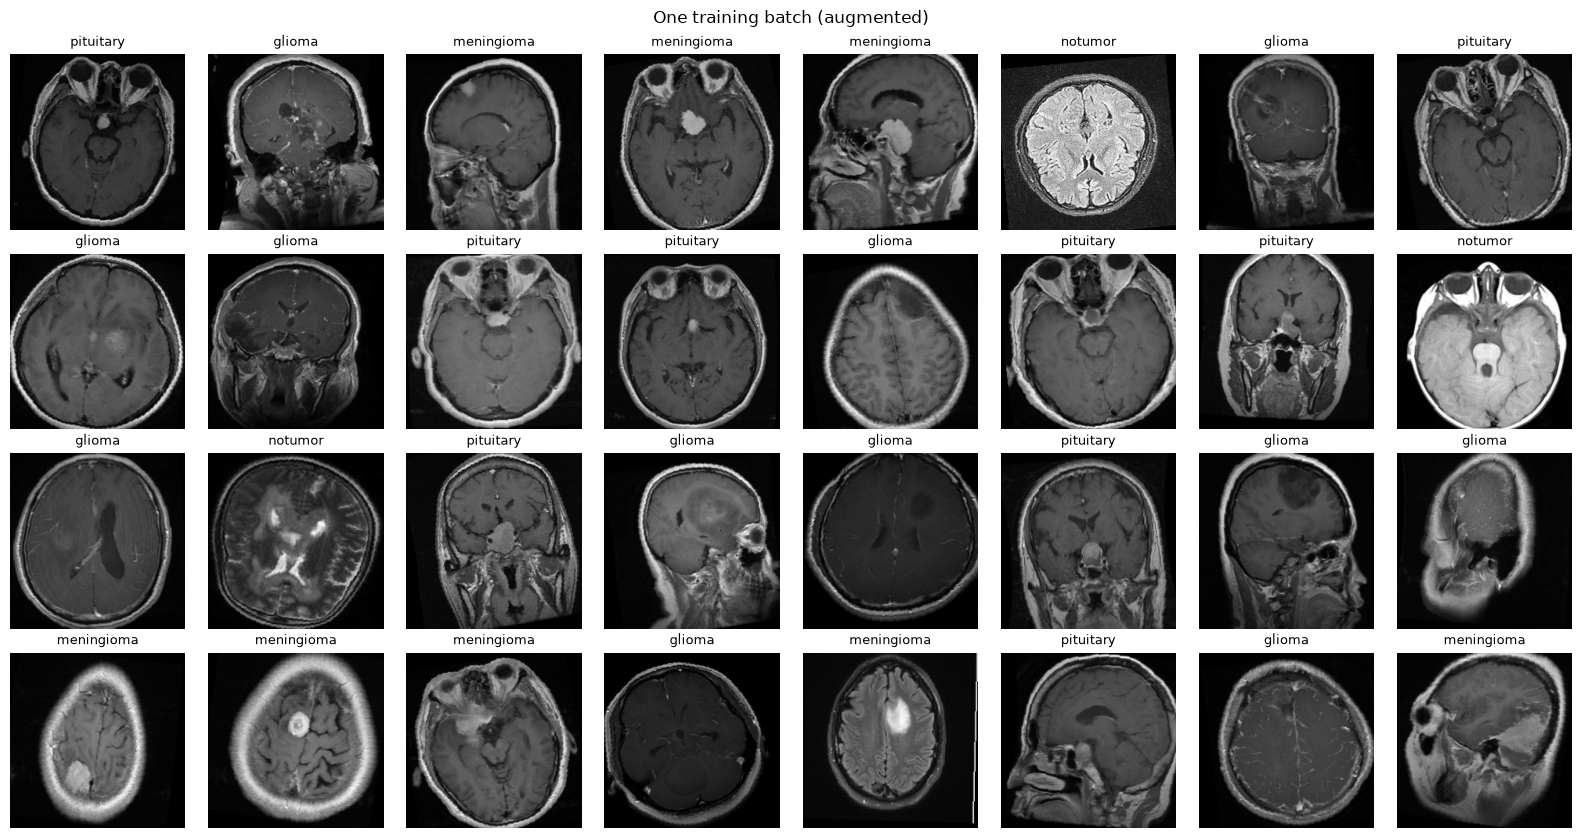

In [10]:
xb, yb = next(iter(train_loader))

print(f"images: {xb.shape}, {xb.dtype}")
print(f"labels: {yb.shape}, {yb.dtype}")
print("per class in this batch:", dict(zip(CLASSES, torch.bincount(yb, minlength=len(CLASSES)).tolist())))

fig, axes = plt.subplots(4, 8, figsize=(16, 8.5))
for ax, img, label in zip(axes.flat, xb, yb):
    ax.imshow(to_display(img))
    ax.set_title(CLASSES[label], fontsize=9)
    ax.axis("off")

plt.suptitle("One training batch (augmented)")
plt.tight_layout()
plt.show()

In [11]:
import time

for epoch in range(2):
    start = time.perf_counter()
    n_images = 0
    for xb, yb in train_loader:
        n_images += len(yb)
    elapsed = time.perf_counter() - start
    print(f"epoch {epoch}: {n_images} images in {elapsed:.1f}s -> {n_images / elapsed:.0f} img/s")

epoch 0: 4214 images in 23.2s -> 182 img/s
epoch 1: 4214 images in 21.5s -> 196 img/s


## Model & training setup

Transfer learning: ResNet18 pretrained on ImageNet (timm), new 4-class head, fine-tuned end-to-end.

In [12]:
MODEL_NAME = "resnet18.a1_in1k"

model = build_model(MODEL_NAME, num_classes=len(CLASSES), pretrained=True)
model = model.to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"{MODEL_NAME}: {n_params / 1e6:.1f}M parameters")
print("classifier head:", model.get_classifier())

resnet18.a1_in1k: 11.2M parameters
classifier head: Linear(in_features=512, out_features=4, bias=True)


In [18]:
from torch import nn

counts = torch.bincount(torch.tensor(train_ds.labels), minlength=len(CLASSES)).float()
class_weights = counts.sum() / (len(CLASSES) * counts)

print("class weights:", {c: round(w, 3) for c, w in zip(CLASSES, class_weights.tolist())})

criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)

class weights: {'glioma': 0.8479999899864197, 'meningioma': 1.0210000276565552, 'notumor': 1.4709999561309814, 'pituitary': 0.8610000014305115}


`train_one_epoch` and `evaluate` live in `src/model.py` (imported in the first cell), so the
`03` notebook and the app use exactly the same code. One epoch:
`zero_grad` → forward → loss → `backward` → `step`; evaluation runs in `eval()` mode under `no_grad`
and returns loss, accuracy and macro-F1.

In [19]:
import math

xb, yb = next(iter(train_loader))
model.eval()
with torch.no_grad():
    logits = model(xb.to(device))
    loss = criterion(logits, yb.to(device))

print(f"logits shape: {logits.shape}")
print(f"initial loss: {loss.item():.3f}  (expected ≈ ln(4) = {math.log(4):.3f})")

logits shape: torch.Size([32, 4])
initial loss: 1.382  (expected ≈ ln(4) = 1.386)


## Training

Model selection on **validation macro-F1**: the best epoch is saved to `models/`. The test set is not used here (→ `03`).

In [20]:
EPOCHS = 20
PATIENCE = 5
CKPT_PATH = ROOT / "models" / "resnet18_best.pt"
CKPT_PATH.parent.mkdir(exist_ok=True)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

history = []
best_f1, best_epoch = 0.0, -1

import time

for epoch in range(EPOCHS):
    start = time.perf_counter()
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer)
    val = evaluate(model, val_loader, criterion)
    lr = optimizer.param_groups[0]["lr"]
    scheduler.step()

    history.append({"epoch": epoch, "train_loss": train_loss, "lr": lr,
                    **{f"val_{k}": v for k, v in val.items()}})

    improved = val["macro_f1"] > best_f1
    if improved:
        best_f1, best_epoch = val["macro_f1"], epoch
        save_checkpoint(CKPT_PATH, model, MODEL_NAME, CLASSES, IMG_SIZE, epoch, val)

    print(f"epoch {epoch:2d} | train loss {train_loss:.3f} | val loss {val['loss']:.3f} "
          f"| val acc {val['acc']:.3f} | val F1 {val['macro_f1']:.3f} | lr {lr:.1e} "
          f"| {time.perf_counter() - start:.0f}s {'*' if improved else ''}")

    if epoch - best_epoch >= PATIENCE:
        print(f"Early stopping: no improvement for {PATIENCE} epochs")
        break

print(f"\nBest val macro-F1: {best_f1:.4f} at epoch {best_epoch}")

epoch  0 | train loss 0.656 | val loss 0.315 | val acc 0.872 | val F1 0.867 | lr 3.0e-04 | 63s *
epoch  1 | train loss 0.235 | val loss 0.144 | val acc 0.949 | val F1 0.949 | lr 3.0e-04 | 43s *
epoch  2 | train loss 0.159 | val loss 0.123 | val acc 0.952 | val F1 0.954 | lr 2.9e-04 | 41s *
epoch  3 | train loss 0.113 | val loss 0.109 | val acc 0.963 | val F1 0.964 | lr 2.8e-04 | 41s *
epoch  4 | train loss 0.080 | val loss 0.087 | val acc 0.971 | val F1 0.972 | lr 2.7e-04 | 42s *
epoch  5 | train loss 0.080 | val loss 0.076 | val acc 0.971 | val F1 0.971 | lr 2.6e-04 | 42s 
epoch  6 | train loss 0.052 | val loss 0.079 | val acc 0.968 | val F1 0.968 | lr 2.4e-04 | 41s 
epoch  7 | train loss 0.039 | val loss 0.082 | val acc 0.973 | val F1 0.974 | lr 2.2e-04 | 41s *
epoch  8 | train loss 0.038 | val loss 0.082 | val acc 0.973 | val F1 0.973 | lr 2.0e-04 | 42s 
epoch  9 | train loss 0.028 | val loss 0.076 | val acc 0.976 | val F1 0.975 | lr 1.7e-04 | 41s *
epoch 10 | train loss 0.020 | val

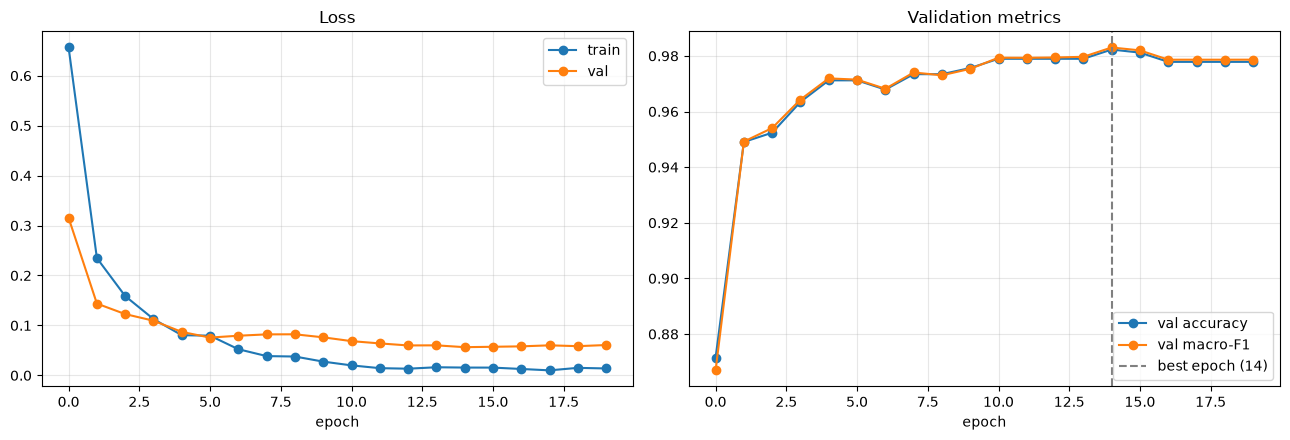

In [21]:
hist = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(hist["epoch"], hist["train_loss"], marker="o", label="train")
axes[0].plot(hist["epoch"], hist["val_loss"], marker="o", label="val")
axes[0].set_title("Loss")
axes[0].set_xlabel("epoch")
axes[0].legend()

axes[1].plot(hist["epoch"], hist["val_acc"], marker="o", label="val accuracy")
axes[1].plot(hist["epoch"], hist["val_macro_f1"], marker="o", label="val macro-F1")
axes[1].axvline(best_epoch, color="gray", linestyle="--", label=f"best epoch ({best_epoch})")
axes[1].set_title("Validation metrics")
axes[1].set_xlabel("epoch")
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
best_model, ckpt = load_checkpoint(CKPT_PATH, device)

check = evaluate(best_model, val_loader, criterion)
print(f"saved at epoch {ckpt['epoch']}, val macro-F1 at save time: {ckpt['val_metrics']['macro_f1']:.4f}")
print(f"reloaded model val macro-F1:            {check['macro_f1']:.4f}")

saved at epoch 14, val macro-F1 at save time: 0.9830
reloaded model val macro-F1:            0.9830


### Observations: training

- Best val macro-F1 **0.983** at epoch 14 (checkpoint reloaded and verified).
- Train loss → ~0.01 while val loss plateaus at ~0.06: the model memorizes the training set,
  but val loss does **not** rise → mild, benign overfitting; best-epoch checkpointing handles it.
- Fluctuations after epoch 14 (±0.004 F1 ≈ 3–4 images) are noise: lr is ~1e-5, weights barely change.
- The selected score is slightly optimistic (max over 20 noisy values) → the unbiased estimate comes from the test set (`03`).
- High accuracy does not prove the model looks at the tumor → Grad-CAM in `03`.